# CS-6600 Project Part 1 - Exploratory Data Analysis

*Weber State University*

Team GuessGPT : Jeffery Hatch, Fred Walter, Isaac Christensen, Zachary Saylors

# Introduction and data source
Our project asks whether we can identify the large language model (LLM) that wrote a paragraph by looking at features of its writing. We are starting with paragraph length, sentence structure, word length, and punctuation. The goal of this first part is to understand the data and decide which measurements are worth testing later, not to claim that we have already built an accurate classifier.

**Original source**: [Name That LLM Kaggle competition (data page)](https://www.kaggle.com/competitions/name-that-llm). The competition was created to identify which of 18 LLMs produced a given passage. Its organizers describe collecting short model-generated responses to prompts covering topics such as philosophy, science, mathematics, computing, and creative writing. These are AI-generated paragraphs, not human-versus-AI examples. The competition describes passages of roughly 40–250 words; counts can differ slightly depending on how words are tokenized.

**Data used here**: We read the team's [CSV copy in GitHub](https://github.com/FredWltr/NameThatLLM/blob/main/dataset/data.csv), rather than downloading the files through Kaggle each time. This copy contains 2,699 labeled paragraphs, written by 18 models in response to 150 distinct prompts. Each row has an id (paragraph identifier), prompt_id (the question or writing prompt), text (generated response), and model (the known authoring model). Each model has 150 responses except claude-fable-5, which has 149 in our copy. We do not know from the notebook why that one record is missing.

This dataset fits the assignment because it gives us labeled examples and enough variation to explore whether measurable writing patterns differ among the 18 possible authors. Responses to the same prompt should stay in the same group during a future train/test split. Otherwise, a classifier could learn topic or wording shared by a prompt rather than patterns that transfer to unseen prompts.

Dataset citation: Yan, Yao; Plomecka, Martyna; and Oldacre, Ashley. Name That LLM. Kaggle, 2026. https://www.kaggle.com/competitions/name-that-llm. The Kaggle data page lists a CC BY-SA 4.0 license.

## Three questions
1. Can we identify the authoring LLM when evaluating responses to prompts not included in the training.
2. How do paragraph length and punctuation use differ between authoring models?
3. Are longer paragraphs easier to classify correctly than shorter paragraphs?

In [47]:
# Load tools for data analysis, visualization, and text processing.
import re
import unicodedata
from collections import Counter

import matplotlib.pyplot as plt
import nltk
import pandas as pd
import seaborn as sns
from nltk.tokenize import sent_tokenize
from sklearn.model_selection import GroupShuffleSplit

# Download NLTK resources for sentence tokenization.
nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Fred\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Fred\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [48]:
# Load the team's copy of the labeled dataset. Each row contains a paragraph, its prompt identifier, and its authoring model.
url = "https://raw.githubusercontent.com/FredWltr/NameThatLLM/refs/heads/main/dataset/data.csv"

data = pd.read_csv(url)
data.head()

,id,prompt_id,text,model
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash
3,009319596f10,p073,Data science communities matter because they t...,gpt-5.6-terra
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",glm-5.3-flash


In [49]:
# Inspect the dataset's size, columns, and an example paragraph to understand what one observation represents.

print("Number of rows:")
print(len(data))

print("\nColumns:")
print(data.columns.tolist())

display(data.head())

print("\nFirst paragraph:")
print(data.loc[0, "text"])

print("\nModel that wrote it:")
print(data.loc[0, "model"])

Number of rows:
2699

Columns:
['id', 'prompt_id', 'text', 'model']


,id,prompt_id,text,model
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash
3,009319596f10,p073,Data science communities matter because they t...,gpt-5.6-terra
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",glm-5.3-flash



First paragraph:
When a language dies, a particular astronomy dims: not only names for stars, but whole grammars of attention that taught speakers how to read the night. Some tongues map the sky by kinship, binding the Milky Way to ancestors, rivers, or the migration paths of birds; others encode lunar phases as verbs, so time is not a line but a recurring breath. A word can carry the exact color of dawn on snow, the etiquette of speaking to thunder, or the mathematics woven into knot calendars and oral star charts. With extinction, those relations collapse into silence. No dictionary can resurrect the sky those speakers inhabited, nor the quiet ethics it taught. We lose metaphors that made the universe intimate, ethical, and alive, cosmologies in which darkness is a listener, comets are warnings carried by relatives, and constellations are not fixed pictures but seasonal responsibilities. The loss is not merely lexical; it is the erasure of possible human answers to wonder. What rema

In [50]:
# Check missing values, exact duplicate paragraphs, and examples per model before deciding whether cleaning or class balancing is needed.
print("Missing values in each column:")
display(data.isna().sum().to_frame("missing_count"))

print("\nNumber of different prompts:")
print(data["prompt_id"].nunique())

print("\nNumber of different LLMs:")
print(data["model"].nunique())

print("\nNumber of paragraphs written by each LLM:")
display(data["model"].value_counts().to_frame("paragraph_count"))

print("\nNumber of repeated identical paragraphs:")
print(data["text"].duplicated().sum())

Missing values in each column:


,missing_count
id,0
prompt_id,0
text,0
model,0



Number of different prompts:
150

Number of different LLMs:
18

Number of paragraphs written by each LLM:


,paragraph_count
model,
qwen3.8-max,150
claude-sonnet-5,150
gemini-3.6-flash,150
gpt-5.6-terra,150
glm-5.3-flash,150
gemini-3.1-pro-preview,150
gemini-3.8-flash,150
claude-opus-4-6,150
gpt-5.6-luna,150



Number of repeated identical paragraphs:
0


**Initial Data-quality review:** The saved checks above report 0 missing values and 0 duplicate passages. This is useful, but a string containing only spaces is not a missing value. The next check makes that distinction without deleting data from the explortory analysis.

In [51]:
# Check for blank/whitespace-only passages without changing the exploratory data.
blank_text = data["text"].fillna("").astype(str).str.strip().eq("")
print("Blank or whitespace-only paragraphs:", int(blank_text.sum()))
print("Duplicate paragraph IDs:", int(data["id"].duplicated().sum()))
print("Duplicate (prompt, model) pairs:", int(data.duplicated(["prompt_id", "model"]).sum()))


Blank or whitespace-only paragraphs: 0
Duplicate paragraph IDs: 0
Duplicate (prompt, model) pairs: 0


,min,median,mean,max
model,,,,
claude-fable-5,39,100.0,112.5,252
claude-opus-4-6,42,98.5,115.1,274
claude-opus-4-8,42,109.0,123.6,251
claude-opus-5,39,116.5,123.4,257
claude-sonnet-5,39,99.5,120.0,267
gemini-3.1-pro-preview,38,104.0,119.3,262
gemini-3.6-flash,40,95.5,111.2,238
gemini-3.7-flash,40,101.5,117.1,252
gemini-3.8-flash,41,84.0,100.7,238


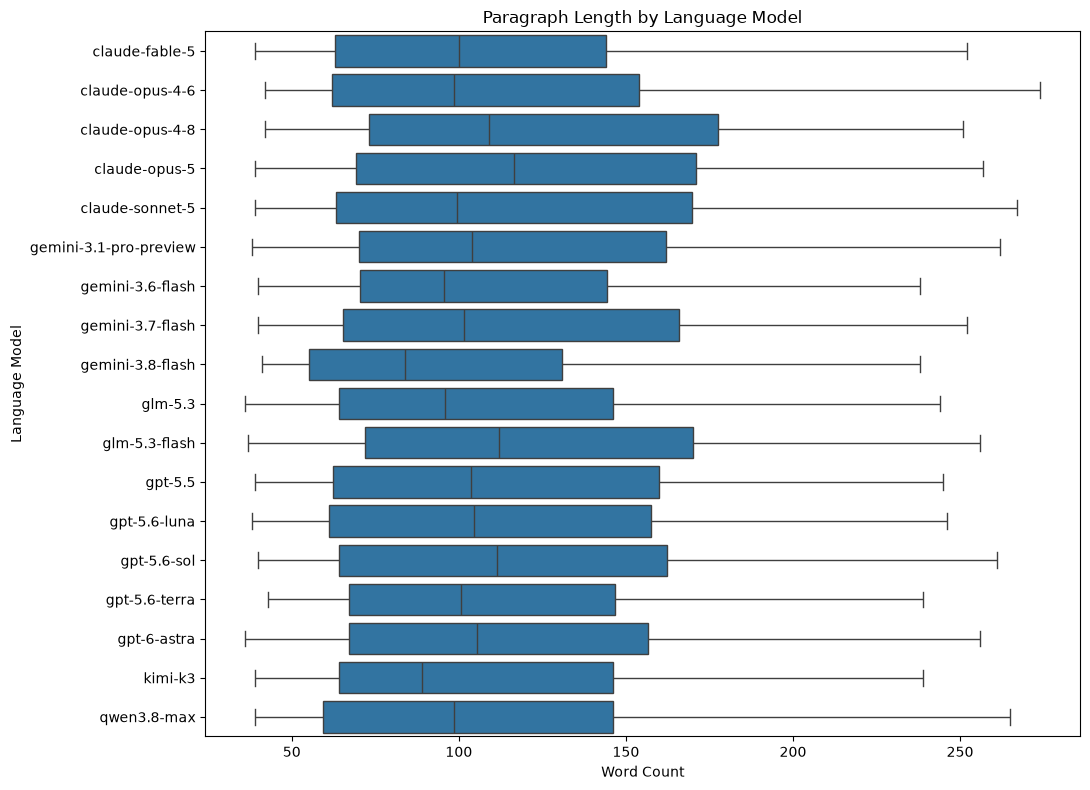

In [52]:
# Compare paragraph length distributions across models. Overlapping distributions may suggest that word count by itself may have limited model identification power.
exploration = data.copy()
exploration["word_count"] = exploration["text"].str.split().str.len()

display(exploration.groupby("model")["word_count"].agg(["min", "median", "mean", "max"]).round(1))

plt.figure(figsize=(11, 8))

sns.boxplot(data=exploration,x="word_count",y="model",order=sorted(exploration["model"].unique()))
plt.title("Paragraph Length by Language Model")
plt.xlabel("Word Count")
plt.ylabel("Language Model")
plt.tight_layout()
plt.show()

In [53]:
# Count whitespace separated tokens in each paragraph. This is an approximate word count and becomes a candidate prediction feature.
data["word_count"] = data["text"].str.split().str.len()

In [54]:
# Calculate average token length using English letter tokens. This measures vocabulary characteristics, but excludes numbers and non English letters.
def average_word_length(text):
    words = re.findall(r'\b[A-Za-z]+\b', str(text))
    return sum(len(word) for word in words) / len(words) if words else 0

data['avg_word_length'] = data['text'].fillna('').apply(average_word_length)

In [55]:
# Use NLTK to separate sentences, then calculate average whitespace separated words per sentence. Sentence boundary mistakes may affect this measurement.
def average_sentence_length(text):
    sentences = sent_tokenize(str(text))

    if not sentences:
        return 0

    word_count = sum(
        len(sentence.split())
        for sentence in sentences
    )

    return word_count / len(sentences)

data['avg_sentence_length'] = data['text'].fillna('').apply(
    average_sentence_length
)

In [56]:
# Count the sentences identified by NLTK. Together with word count, this describes how a paragraph is structured.
data['sentence_count'] = data['text'].fillna('').apply(
    lambda x: len(sent_tokenize(x))
)

In [57]:
# Count Unicode punctuation characters, including em dashes and curly apostrophes.
def count_punctuation(text):
    return sum(
        unicodedata.category(char).startswith("P")
        for char in str(text)
    )

data["punctuation_count"] = data["text"].fillna("").apply(count_punctuation)

data["punctuation_per_100_words"] = (
    data["punctuation_count"] / data["word_count"].clip(lower=1) * 100
)

In [58]:
# Count Unicode symbols, including mathematical and currency symbols.
def count_symbols(text):
    return sum(
        1 for char in str(text)
        if unicodedata.category(char)[0] == 'S'
    )

data['symbol_count'] = data['text'].fillna('').apply(count_symbols)

In [59]:
# Identify punctuation and symbols.

# Combine all text into one string
all_text = data['text'].fillna('').astype(str).str.cat(sep='')

# Get punctuation counts
punctuation_counts = Counter(
    char for char in all_text
    if unicodedata.category(char).startswith("P")
)
punctuation_list = list(punctuation_counts)

# Get symbol counts
symbol_counts = Counter(
    char for char in all_text
    if unicodedata.category(char).startswith("S")
)

# Print counts
print("Number of punctuation types:")
print(len(punctuation_list))
display(pd.DataFrame(punctuation_counts.most_common(), columns=["Punctuation", "Count"]))

print("\nNumber of symbol types:")
print(len(symbol_counts))
display(pd.DataFrame(symbol_counts.most_common(), columns=["Symbol", "Count"]))

Number of punctuation types:
24


,Punctuation,Count
0,",",27962
1,.,13054
2,—,1835
3,:,1821
4,-,1592
5,',1475
6,;,1331
7,’,840
8,"""",270
9,“,125



Number of symbol types:
12


,Symbol,Count
0,^,20
1,+,20
2,−,12
3,=,11
4,⁻,7
5,⁺,2
6,$,1
7,<,1
8,∞,1
9,°,1


In [60]:
# Calculate each punctuation character's share of total counted punctuation. Using a minimum denominator of one prevents division by zero.

punctuation_total = data["punctuation_count"].clip(lower=1)

for p in punctuation_list:
    count = (data["text"].fillna("").astype(str).str.count(re.escape(p)))

    data[f"ratio_{p}"] = count / punctuation_total

In [61]:
# Preview the original columns alongside the newly created numerical writing features.
data

,id,prompt_id,text,model,word_count,avg_word_length,avg_sentence_length,sentence_count,punctuation_count,punctuation_per_100_words,...,ratio_(,ratio_),ratio_/,ratio__,ratio_{,ratio_},ratio_\,ratio_–,ratio_[,ratio_]
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max,192,4.782383,24.000000,8,29,15.104167,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5,65,6.611940,16.250000,4,11,16.923077,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash,77,5.012987,19.250000,4,12,15.584416,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,009319596f10,p073,Data science communities matter because they t...,gpt-5.6-terra,220,6.576577,24.444444,9,45,20.454545,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",glm-5.3-flash,97,4.343434,24.250000,4,15,15.463918,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2694,ff4344ceda23,p075,"Across centuries of silence and shadow, an inv...",gemini-3.8-flash,156,5.668790,26.000000,6,21,13.461538,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2695,ff507658ba82,p092,Though both instruments breathe the exact same...,gemini-3.7-flash,74,6.094595,18.500000,4,12,16.216216,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2696,ff50c252810c,p113,A single photon leaves the star as neither wav...,claude-opus-4-8,83,4.506024,20.750000,4,12,14.457831,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2697,ffcf6321f7e9,p073,Data science communities matter because they t...,glm-5.3,83,6.929412,16.600000,5,17,20.481928,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


,word_count,avg_word_length,avg_sentence_length,sentence_count,punctuation_count,symbol_count,punctuation_per_100_words
count,2699.00,2699.00,2699.00,2699.00,2699.00,2699.00,2699.00
mean,114.66,5.39,24.03,4.86,18.83,0.03,17.08
std,58.28,0.53,10.35,2.17,9.40,0.27,4.45
min,36.00,3.84,9.20,1.00,1.00,0.00,1.04
25%,64.00,5.02,19.60,3.00,11.00,0.00,14.00
50%,101.00,5.35,22.80,5.00,17.00,0.00,16.51
75%,157.00,5.72,26.50,6.00,25.00,0.00,19.35
max,274.00,7.37,220.00,14.00,98.00,6.00,70.00


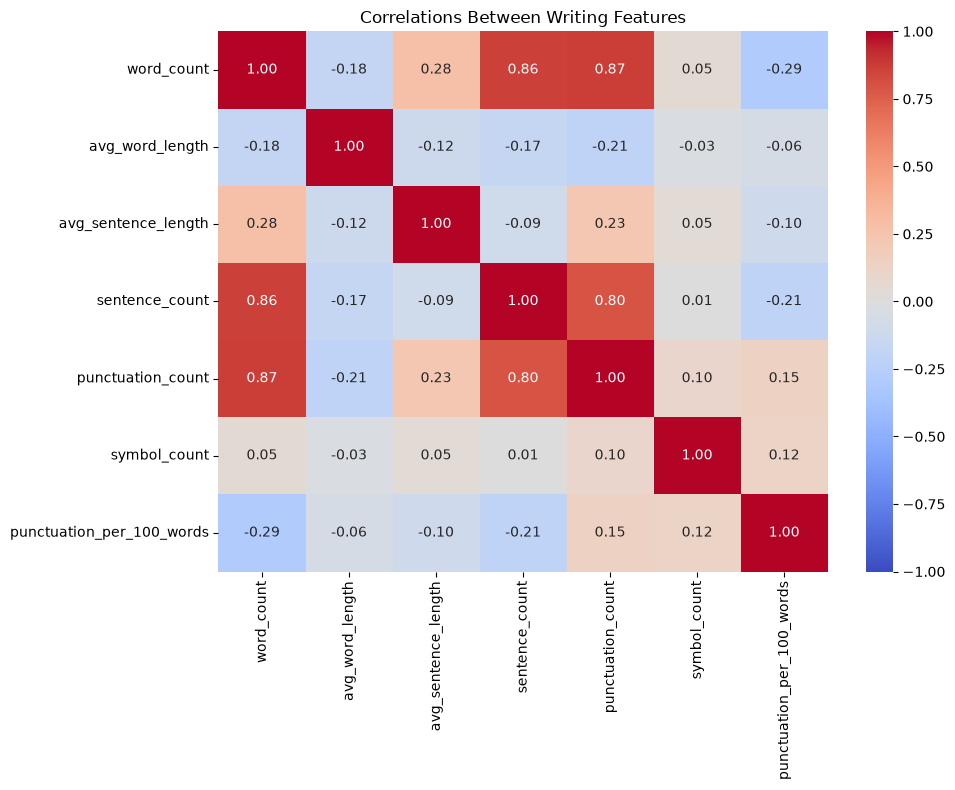

In [62]:
# Measure punctuation relative to paragraph length and look at correlations between numerical features. Correlation describes relationships, it does not establish prediction accuracy.
feature_columns = [
    "word_count",
    "avg_word_length",
    "avg_sentence_length",
    "sentence_count",
    "punctuation_count",
    "symbol_count",
    "punctuation_per_100_words"
]

display(data[feature_columns].describe().round(2))

correlations = data[feature_columns].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlations,annot=True,fmt=".2f",cmap="coolwarm",center=0,vmin=-1,vmax=1)
plt.title("Correlations Between Writing Features")
plt.tight_layout()
plt.show()

# Length and correlation takeaways
Word count varies a lot within each model, with model means ranging from 101 to 124 words. The correlation heatmap shows that raw punctuation count and sentence count largely track paragraph length (r = 0.87 and r = 0.86, respectively). Normalized punctuation rates are  more useful comparison across short and long passages. These observations guide feature selection, but they are not evidence of predictive accuracy.

In [63]:
# Flag unusual sentence lengths and punctuation rates using the 1.5 * IQR rule. Inspect examples to distinguish legitimate writing patterns from measurement or data errors.
features_to_review = ["avg_sentence_length","punctuation_per_100_words"]

for feature in features_to_review:
    # Calculate the range containing the middle half of the values.
    q1 = data[feature].quantile(0.25)
    q3 = data[feature].quantile(0.75)
    iqr = q3 - q1

    # 1.5 * IQR rule to flag any outliers.
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr
    flagged = data.loc[(data[feature] < lower_limit)| (data[feature] > upper_limit)]

    print(f"\nFeature: {feature}")
    print(f"Review limits: {lower_limit:.2f} to {upper_limit:.2f}")
    print(f"Number of flagged paragraphs: {len(flagged)}")

    display(flagged[["id", "model", feature]])

    # Read the paragraph with the largest value to understand the flag.
    if not flagged.empty:
        largest_index = flagged[feature].idxmax()

        print("Paragraph with the largest flagged value:")
        print(data.loc[largest_index, "text"])


Feature: avg_sentence_length
Review limits: 9.25 to 36.85
Number of flagged paragraphs: 91


,id,model,avg_sentence_length
7,010b4f492abc,claude-opus-4-6,38.5
15,018b5e011a51,claude-opus-4-6,50.0
30,0324d70bc185,claude-sonnet-5,41.0
37,0408e914e870,kimi-k3,41.0
49,050837aef9a3,claude-fable-5,51.0
...,...,...,...
2446,eabb7436c119,gpt-5.6-sol,49.0
2475,ecbdee773f9c,glm-5.3,42.0
2487,ee1d6ad0ec5f,claude-opus-4-6,38.5
2497,ef69f5a64ab3,gpt-5.6-terra,45.2


Paragraph with the largest flagged value:
Cold light piercing the blinds, blue-white striping the duvet where my toes kick out numb, static buzzing in the radiator, wait, did I leave the kettle on, no, that was yesterday or in the dream with the red umbrella floating past the office window three stories up where the printer jammed again, red light flashing paper jam feed tray two, god, my neck is stiff like dried glue on cardboard, turning slowly to the tick-tick-ticking of the wall clock counting down to seven thirty, no, seven thirty-four already, late, the train won't wait for anyone, especially not me with one shoe missing somewhere under the dust bunnies behind the wardrobe where old letters smell like dried lavender and damp cellar dirt, breathe in through the nose, out through the mouth like that meditation video said, but my ribs feel tight, wrapped in copper wire, hum of the refrigerator kicking on, low vibration through the floorboards into my heels, is it raining outside, th

,id,model,punctuation_per_100_words
77,079b7e92792c,glm-5.3-flash,28.571429
84,07f409f75b21,gpt-5.6-luna,27.450980
112,0b7978dfe5a8,gpt-5.6-sol,27.906977
182,1275d7931666,claude-sonnet-5,29.166667
222,16b9932865c9,gpt-5.5,31.818182
...,...,...,...
2380,e4eda9323e11,kimi-k3,27.536232
2436,e9b931ba29e9,gpt-5.6-terra,28.846154
2437,e9c0a461e3d3,glm-5.3,27.777778
2557,f3f0e5d9b09d,claude-fable-5,28.260870


Paragraph with the largest flagged value:
Let \(T\) be a consistent formal theory, and let \(T^+\) extend \(T\) with a truth predicate or stronger induction. A theorem \(\varphi\) may require millions of symbols in \(T\), yet admit a one-line proof in \(T^+\): “By the certified induction principle, \(\varphi\).” This is Gödelian speedup: leaving the original framework does not shorten reasoning; it makes previously inaccessible justification available.


# Outlier review
The 1.5 x IQR checks flag 91 resposnes with unusual average sentence lengths (outside of ~9.25-36.85 words) and 67 with unusual punctuation rates (outside  of ~5.97-27.39 marks per 100 words). The flags are not necessarily distinct rows, and being outside these ranges does not indicate the data is wrong.

The longest observed average sentence length is 220 words. The example printed above is a stream-of-consciousness passage with a long chain of clauses. Although unusual, it is coherent as a writing style and should be kept. The largest observed punctuation rate is 70 marsk per 100 words. Its example is a mathematical explanation containing LaTeX-style commands and backslashes, so the high rate may partly reflect formatting rather than sentence punctuation. We should keep the source text and document that limitation instead of deleting it or arbitrarily reducing its value.

The decision is to keep all currently flagged passages for the initial analysis. Investigate obvious parsing/markup artifacts separately if they become problematic in modeling. If a future validation step finds turly empty, malformed, or mislabeled rows, handle those as specific quality problems and document the number removed.

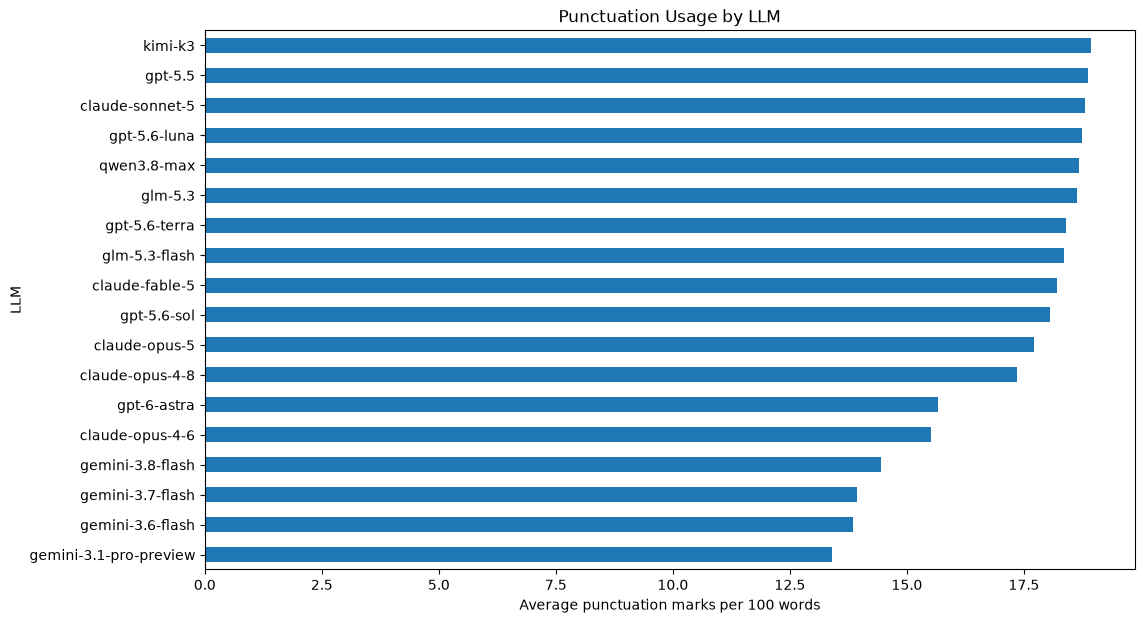

In [64]:
# Additional visualization to compare average punctuation usage across LLMs.
punctuation_by_model = (
    data.groupby("model")["punctuation_per_100_words"]
    .mean()
    .sort_values()
)

punctuation_by_model.plot(kind="barh", figsize=(12, 7))

plt.xlabel("Average punctuation marks per 100 words")
plt.ylabel("LLM")
plt.title("Punctuation Usage by LLM")
plt.show()

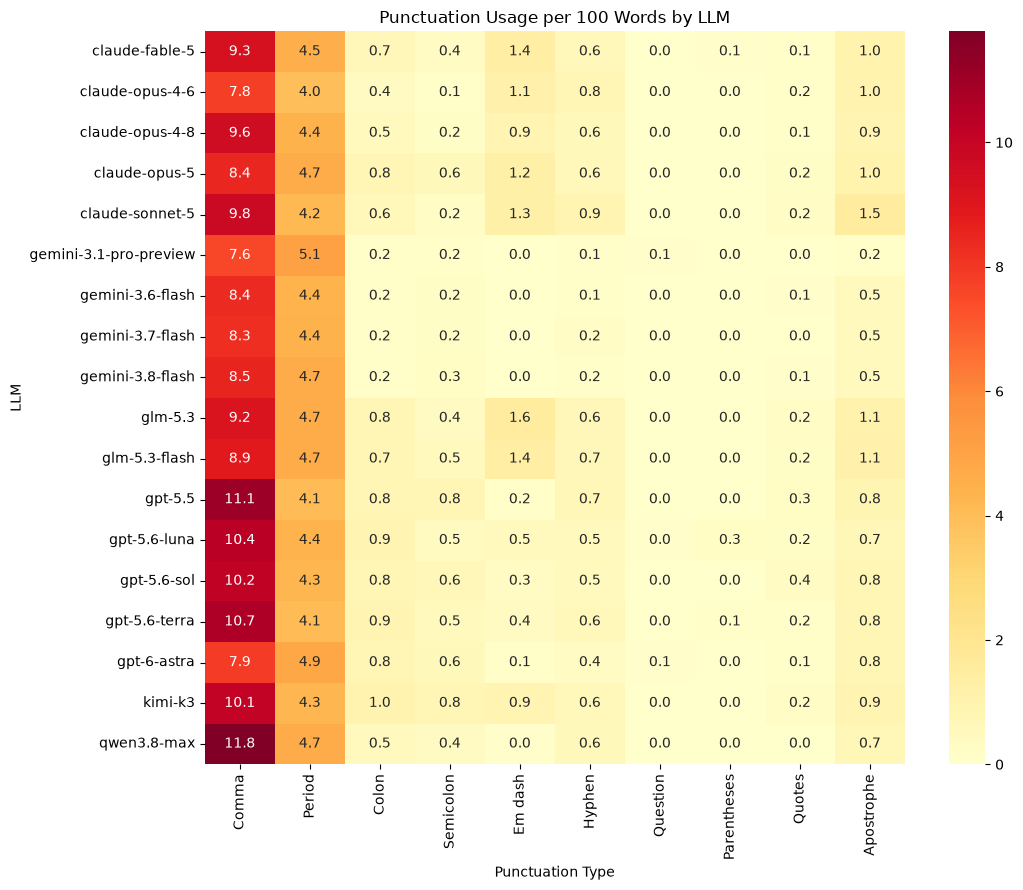

In [65]:
# Compare individual punctuation rates per 100 words.
punctuation_marks = {
    "Comma": ",",
    "Period": ".",
    "Colon": ":",
    "Semicolon": ";",
    "Em dash": "—",
    "Hyphen": "-",
    "Question": "?",
    "Parentheses": "()",
    "Quotes": '"“”',
    "Apostrophe": "'’",
}

for name, marks in punctuation_marks.items():
    pattern = "[" + re.escape(marks) + "]"

    data[name] = (
        data["text"].fillna("").str.count(pattern)
        / data["word_count"].clip(lower=1) * 100
    )


punctuation_by_model = data.groupby("model")[list(punctuation_marks)].mean()

plt.figure(figsize=(11, 9))
sns.heatmap(punctuation_by_model, annot=True, fmt=".1f", cmap="YlOrRd")
plt.title("Punctuation Usage per 100 Words by LLM")
plt.xlabel("Punctuation Type")
plt.ylabel("LLM")
plt.tight_layout()
plt.show()

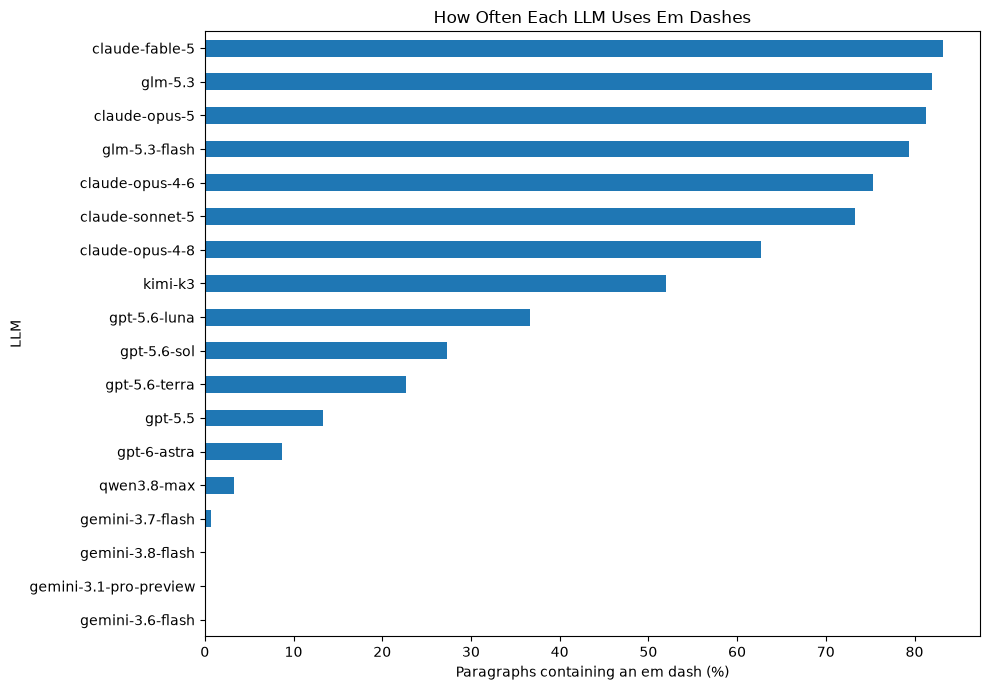

In [66]:
# Percentage of paragraphs containing at least one em dash, by model.
em_dash_usage = (
    data.assign(has_em_dash=data["text"].fillna("").str.contains("—", regex=False))
    .groupby("model")["has_em_dash"]
    .mean()
    .mul(100)
    .sort_values()
)

plt.figure(figsize=(10, 7))
em_dash_usage.plot(kind="barh")

plt.xlabel("Paragraphs containing an em dash (%)")
plt.ylabel("LLM")
plt.title("How Often Each LLM Uses Em Dashes")
plt.tight_layout()
plt.show()

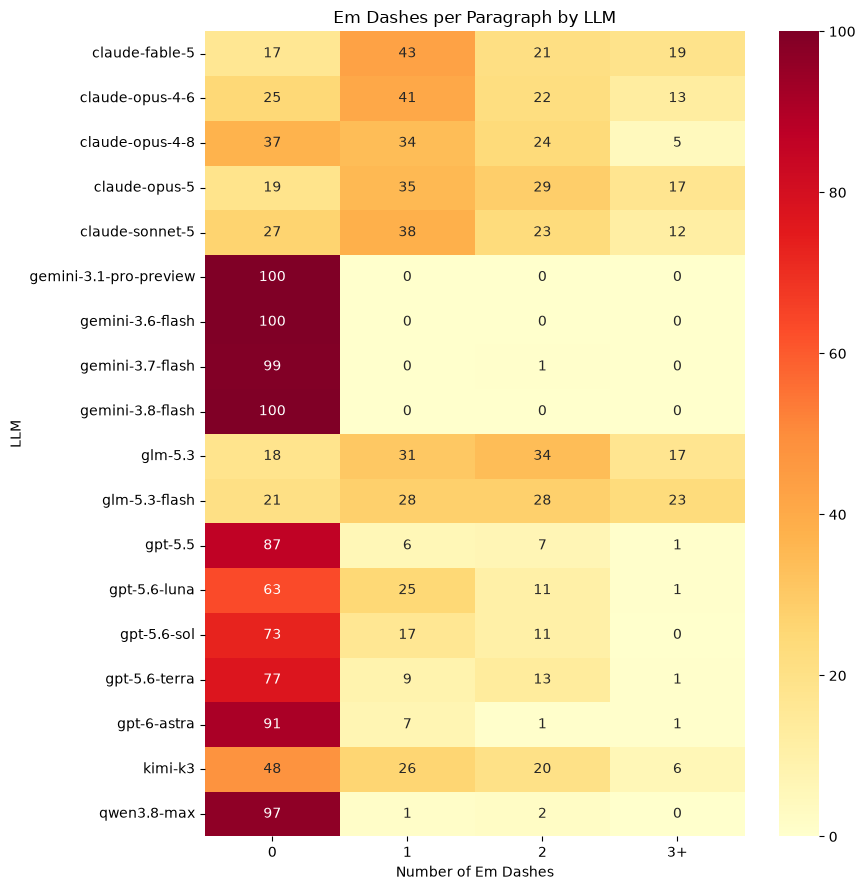

In [67]:
# Categorize paragraphs by their number of em dashes.
em_dash_counts = data["text"].fillna("").str.count("—")

em_dash_categories = em_dash_counts.clip(upper=3).map({
    0: "0",
    1: "1",
    2: "2",
    3: "3+",
})

em_dash_distribution = pd.crosstab(
    data["model"],
    em_dash_categories,
    normalize="index"
).mul(100)

# Keep columns in numerical order, including absent categories.
em_dash_distribution = em_dash_distribution.reindex(
    columns=["0", "1", "2", "3+"],
    fill_value=0
)

plt.figure(figsize=(9, 9))
sns.heatmap(
    em_dash_distribution,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd"
)

plt.title("Em Dashes per Paragraph by LLM")
plt.xlabel("Number of Em Dashes")
plt.ylabel("LLM")
plt.tight_layout()
plt.show()

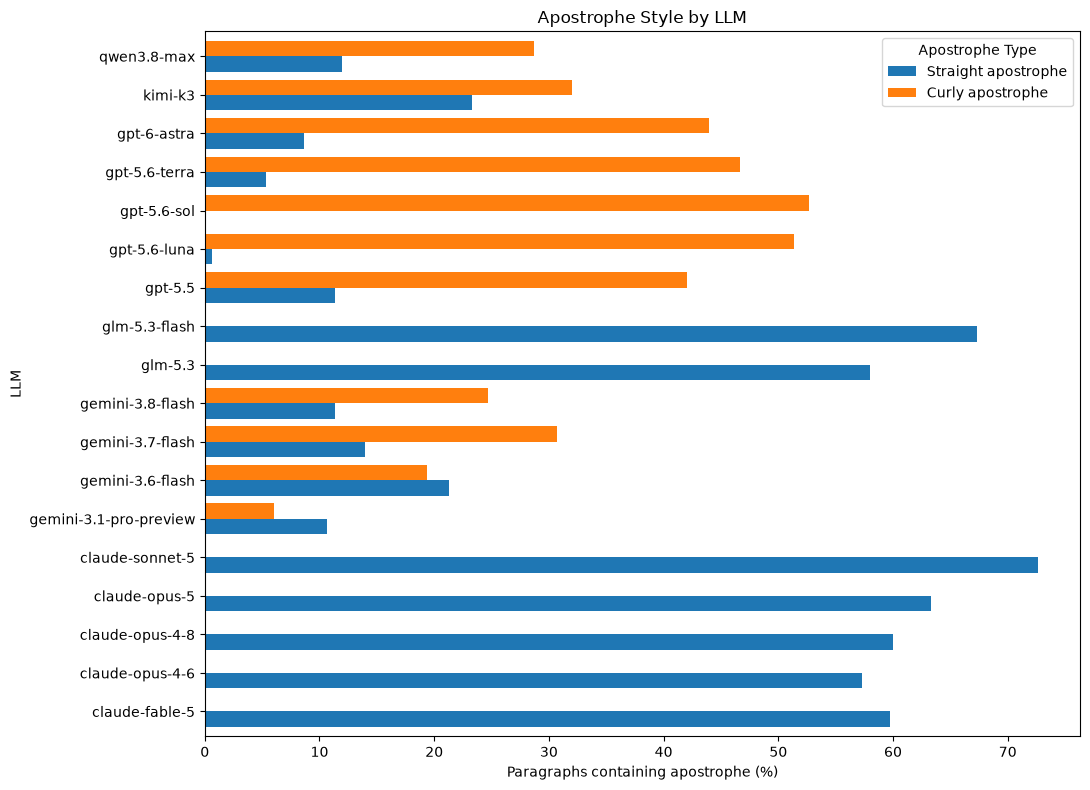

In [68]:
# Percentage of paragraphs containing each apostrophe style.
apostrophe_styles = {
    "Straight apostrophe": "'",
    "Curly apostrophe": "’",
}

for name, char in apostrophe_styles.items():
    data[name] = data["text"].fillna("").str.contains(char, regex=False)

apostrophe_usage = (
    data.groupby("model")[list(apostrophe_styles)]
    .mean()
    .mul(100)
)

apostrophe_usage.plot.barh(figsize=(11, 8), width=0.8)

plt.title("Apostrophe Style by LLM")
plt.xlabel("Paragraphs containing apostrophe (%)")
plt.ylabel("LLM")
plt.legend(title="Apostrophe Type")
plt.tight_layout()
plt.show()

## Observations:



The dataset is nearly balanced by model: 17 models have 150 responses and claude-fable-5 has 149. There are 150 unique prompts, and the existing checks found no missing values or exact duplicate paragraphs. However, missing-value counts do not detect strings made entirely of whitespace, so we check those separately below.

**Paragraph and sentence length**: Across all 2,699 responses, the average paragraph contains 114.66 whitespace-separated words; the median is 101 and the middle half ranges from 64 to 157. The model-level means overlap considerably: gemini-3.8-flash averages about 100.7 words, while claude-opus-4-8 averages about 123.6. The boxplot shows variation within each model, so paragraph length alone is unlikely to identify all 18 models reliably. The typical paragraph has 5 sentences (median), with a median average sentence length of 22.8 words.

**Correlations**: Word count is strongly related to punctuation count (r = 0.87) and sentence count (r = 0.86), which is reasonable because longer paragraphs tend to contain more of both. For this reason, we should compare punctuation per 100 words instead of relying only on raw counts. Overall punctuation density has a weak negative correlation with word count (r = -0.29); the heatmap describes feature relationships, not classification accuracy. Symbol count is close to zero in most paragraphs and does not currently look like a strong baseline feature.

**Punctuation differences by model**: Overall punctuation density averages 17.08 marks per 100 words, with a median of 16.51. The model-specific heatmap reveals clearer patterns than total punctuation alone. Qwen averages about 11.8 commas per 100 words, while GPT-5.5 averages about 11.1. Em dashes are particularly distinctive: roughly 83% of claude-fable-5 paragraphs contain an em dash, compared with almost none of the Gemini paragraphs. Claude and GLM models also frequently use multiple em dashes within a single paragraph.

Apostrophe style varies across model families. Claude and GLM generally favor straight apostrophes, while GPT models favor curly apostrophes. Gemini shows more variation, and Kimi and Qwen use both styles. Some GPT models and Kimi also show relatively greater semicolon usage. These differences may help identify the generating model, although some formatting patterns could reflect postprocessing rather than the model's underlying writing style.

Taken together, the graphs suggest that a combination of length, sentence structure, and specific punctuation habits is worth testing. They do not yet tell us how accurately a model will classify new paragraphs. We will need to measure that on prompts held out from training.

## Feature selection and cleaning decisions
For a first classifier, we propose using `word_count, avg_word_length, avg_sentence_length, punctuation_per_100_words`, and normalized rates for commas, semicolons, em dashes, and both apostrophe styles. We are leaving `raw punctuation_count` and `sentence_count` out of this initial feature list because each is strongly correlated with word count. We will keep their existing exploratory calculations and can test them later. `symbol_count` also stays in the descriptive analysis but not the initial model because most rows have zero symbols.

### Cleaning and edge cases:
- Preserve the original passage text and its case, apostrophe shape, and em dashes. These differences might be useful for attribution. We trim leading/trailing whitespace in a separate modeling copy only; the raw dataset is unchanged.
- Report and remove rows with missing/blank/punctuation-only text from the modeling copy rather than inventing word counts or dividing by zero. There were zero NaN values in the saved output, but that is not itself a check for whitespace-only strings.
- The total punctuation count already includes all characters in the Unicode punctuation categories. The original per-type heatmap counts only a chosen subset. We will also recognize exclamation marks, em dashes, ellipses, slashes/backslashes, brackets, underscores, and other punctuation when auditing text. Mathematical operators such as + and = are Unicode symbols, not punctuation. We will not pretend they were covered by punctuation ratios.
- The very high punctuation sample contains LaTeX-style math delimiters, and its backslashes count as punctuation under the existing Unicode method. For now we keep it, note the measurement limitation, and may later test whether excluding math markup improves results. We will not silently strip mathematical content or replace unusual values with medians.
- Keep legitimate outliers. The IQR check is a review flag, not proof that a passage is incorrect. Do not remove a response just because it has long sentences or heavy punctuation.

### Handling Categorical Variables
- The `model` column is our target label (`y`), representing which LLM generated each paragraph. It will not be included among the input features.
- The `id` column uniquely identifies each paragraph and will be excluded from modeling because it does not represent writing style.
- The `prompt_id` column identifies the prompt associated with each response. We will use it to group responses during the train/test split, ensuring that paragraphs generated from the same prompt do not appear in both sets. It will not be used as a predictive feature.
- The `text` column contains the original paragraphs. Rather than encoding the raw text as a categorical variable, we will extract numerical writing-style features from it for our initial classifier.

## Data Preprocessing

Based on our exploratory analysis, we identified several writing-style characteristics that may help distinguish between LLMs, including text length, sentence structure, and punctuation usage. We will use these observations to prepare a consistent set of numerical features for modeling.

The following reusable functions clean the raw text, extract our selected writing-style features, and separate the model labels from the input features. We will also split the data by prompt ID to prevent responses to the same prompt from appearing in both the training and testing sets.

This prepares our dataset for modeling while avoiding data leakage.

In [69]:
FEATURE_COLUMNS = [
    "word_count",
    "avg_word_length",
    "avg_sentence_length",
    "punctuation_per_100_words",
    "comma_per_100_words",
    "semicolon_per_100_words",
    "em_dash_per_100_words",
    "straight_apostrophe_per_100_words",
    "curly_apostrophe_per_100_words",
]


def clean_text(raw_data):
    """Keep usable passages and the columns needed for modeling."""
    df = raw_data[["text", "model", "prompt_id"]].copy()
    df["text"] = df["text"].fillna("").str.strip()
    return df.loc[df["text"].str.contains(r"[^\W_]", regex=True)].copy()


def extract_style_features(text):
    """Calculate nine numerical writing-style features for one passage."""
    words = text.split()
    word_count = len(words)

    letter_words = re.findall(r"\b[A-Za-z]+\b", text)
    avg_word_length = (
        sum(map(len, letter_words)) / len(letter_words)
        if letter_words else 0
    )

    sentences = sent_tokenize(text)
    avg_sentence_length = (
        sum(len(sentence.split()) for sentence in sentences) / len(sentences)
        if sentences else 0
    )

    punctuation_count = sum(
        unicodedata.category(char).startswith("P") for char in text
    )

    def rate(characters):
        return sum(text.count(char) for char in characters) / word_count * 100

    return {
        "word_count": word_count,
        "avg_word_length": avg_word_length,
        "avg_sentence_length": avg_sentence_length,
        "punctuation_per_100_words": punctuation_count / word_count * 100,
        "comma_per_100_words": rate(","),
        "semicolon_per_100_words": rate(";"),
        "em_dash_per_100_words": rate("—"),
        "straight_apostrophe_per_100_words": rate("'"),
        "curly_apostrophe_per_100_words": rate("’"),
    }


def prepare_features(raw_data):
    """Return numeric features X, model labels y, and prompt groups."""
    df = clean_text(raw_data)
    X = pd.DataFrame(
        [extract_style_features(text) for text in df["text"]],
        index=df.index,
        columns=FEATURE_COLUMNS,
    )
    y = df["model"]
    groups = df["prompt_id"]
    return X, y, groups

In [70]:
X, y, groups = prepare_features(data)

print("Feature shape:", X.shape)
print("Labels:", y.shape)
print("Prompt groups:", groups.nunique())

display(X.head())

Feature shape: (2699, 9)
Labels: (2699,)
Prompt groups: 150


,word_count,avg_word_length,avg_sentence_length,punctuation_per_100_words,comma_per_100_words,semicolon_per_100_words,em_dash_per_100_words,straight_apostrophe_per_100_words,curly_apostrophe_per_100_words
0,192,4.782383,24.000000,15.104167,8.854167,1.041667,0.000000,0.0,0.520833
1,65,6.611940,16.250000,16.923077,7.692308,0.000000,0.000000,0.0,0.000000
2,77,5.012987,19.250000,15.584416,10.389610,0.000000,0.000000,0.0,0.000000
3,220,6.576577,24.444444,20.454545,14.545455,0.454545,0.000000,0.0,0.000000
4,97,4.343434,24.250000,15.463918,8.247423,0.000000,2.061856,0.0,0.000000


In [71]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42,
)

train_idx, test_idx = next(splitter.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print("Training:", X_train.shape)
print("Testing:", X_test.shape)
print("Shared prompts:",
      len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])))

Training: (2159, 9)
Testing: (540, 9)
Shared prompts: 0


## Final Research Question

How well can simple writing-style features identify which of the 18 LLMs wrote a response when its prompt was not included in training?

**Evaluation:**
We will use the paragraph length, word length, sentence structure, and punctuation features prepared above. We will keep responses to the same prompt together when splitting the data, using about 80% of the prompts for training and 20% for testing.

We will use balanced accuracy as our main metric and also report macro F1. We will compare our results against a simple baseline that always guesses the most common training label. A confusion matrix will show which LLMs are most often confused with each other.

Any model tuning will use cross-validation within the training portion, keeping responses to the same prompt together in each fold. The test portion will be used to evaluate the selected approach.

We will judge how useful these features are by how much our classifier improves over the baseline on held-out prompts and how consistent the results are across validation folds. If the results are close to the baseline, that would still help answer our question by showing that the features and methods we tested were not very useful for identifying the LLMs in this dataset.

We chose our initial features after looking at all 2,699 labeled rows during EDA. This could make our test results look better than they would on entirely new data, so we will acknowledge that limitation when discussing our results.

We could also compare against a classifier using only word count to see whether the other features improve on paragraph length alone.